# DQN - Lunar Lander

## 0. Setup, seeds, hyperparameters (with reasons)

In [1]:
import time
import numpy as np
import torch
import matplotlib.pyplot as plt

from common import (
    make_env, set_seed, run_episode, evaluate,
    plot_training, moving_average, end_reason, ENV_ID,
)

SEEDS = [0, 1, 2]
SEED = SEEDS[0]
set_seed(SEED)
print("imports OK")

imports OK


### Prediction (written BEFORE running)
- Mean score: about -200 (range -300 to -100)
- Most common end reason: crash.
- Episode length: about 45 moments, because of not knowing where to press 
- Why: a random agent never controls its fall, so it hits the ground fast and hard.

 all the attempts fail, pilot doesn't hit proper buttons only rondom buttons and that causes the rocket to fall drastically 

### Result (written AFTER running)
- Mean score: -192 (I predicted -200: close)
- Most common ending: crash, 92 out of 100 (I predicted crash: correct)
- Average length: 90 moments (I predicted 45: off by about double)
  do-nothing length: 70.4
- I was off on the length because gravity played a role in this where it took about 70 and the other 20 i just random buttons being pressed  .

##  Random agent baseline


In [2]:
# --- Random agent baseline: 100 episodes, no learning ---
env_baseline = make_env(seed=SEED)        # eval env, no rendering

def random_policy(state):
    return env_baseline.action_space.sample()

baseline = evaluate(env_baseline, random_policy, n_episodes=100, seed=SEED)
env_baseline.close()

print(f"\nRandom baseline: mean={baseline['mean']:.1f}  "
      f"std={baseline['std']:.1f}")
print("Target to beat: mean >= 200 (spec)")
print("average length:", baseline["steps"].mean())
do_nothing = evaluate(make_env(seed=SEED), lambda s: 0, n_episodes=100, seed=SEED)
print("do-nothing length:", do_nothing["steps"].mean())

Eval over 100 episodes (no exploration):
  mean=-192.08  std=114.45  min=-462.47  max=8.27
  end reasons: {'crash': 92, 'out_of_viewport': 8}

Random baseline: mean=-192.1  std=114.4
Target to beat: mean >= 200 (spec)
average length: 90.03
Eval over 100 episodes (no exploration):
  mean=-136.70  std=49.51  min=-335.37  max=-0.98
  end reasons: {'crash': 100}
do-nothing length: 70.4


## 1. Environment initialization

In [3]:
env = make_env(seed=SEED)

STATE_DIM = env.observation_space.shape[0]
N_ACTIONS = env.action_space.n
print("state size:", STATE_DIM, "| number of actions:", N_ACTIONS)

state size: 8 | number of actions: 4


## 2.Thruster experiment 

In [4]:
names = {0: "do nothing", 1: "left thruster", 2: "main engine", 3: "right thruster"}
for button in range(N_ACTIONS):
    state, _ = env.reset(seed=0)
    before = state.copy()
    for _ in range(15):
        state, *_ = env.step(button)
    print(f"{names[button]:15s} sideways speed {before[2]:+.2f} -> {state[2]:+.2f}"
          f" | spin {before[5]:+.2f} -> {state[5]:+.2f}"
          f" | fall speed {before[3]:+.2f} -> {state[3]:+.2f}")

do nothing      sideways speed +0.58 -> +0.58 | spin -0.13 -> -0.13 | fall speed -0.53 -> -0.93
left thruster   sideways speed +0.58 -> +0.43 | spin -0.13 -> +0.46 | fall speed -0.53 -> -0.93
main engine     sideways speed +0.58 -> +0.65 | spin -0.13 -> -0.11 | fall speed -0.53 -> -0.18
right thruster  sideways speed +0.58 -> +0.73 | spin -0.13 -> -0.74 | fall speed -0.53 -> -0.94


## 3. Replay buffer

the recording notebook for the pilot 

In [5]:
class ReplayBuffer:
    def __init__(self, capacity, state_dim):
        self.capacity, self.size, self.pos = capacity, 0, 0
        self.s  = np.zeros((capacity, state_dim), dtype=np.float32)
        self.a  = np.zeros(capacity, dtype=np.int64)
        self.r  = np.zeros(capacity, dtype=np.float32)
        self.s2 = np.zeros((capacity, state_dim), dtype=np.float32)
        self.d  = np.zeros(capacity, dtype=np.float32)   # 1 only if truly ended

    def add(self, s, a, r, s2, terminated):
        i = self.pos
        self.s[i], self.a[i], self.r[i], self.s2[i] = s, a, r, s2
        self.d[i] = float(terminated)
        self.pos = (self.pos + 1) % self.capacity
        self.size = min(self.size + 1, self.capacity)

    def sample(self, batch_size):
        idx = np.random.randint(0, self.size, size=batch_size)
        return (torch.from_numpy(self.s[idx]), torch.from_numpy(self.a[idx]),
                torch.from_numpy(self.r[idx]), torch.from_numpy(self.s2[idx]),
                torch.from_numpy(self.d[idx]))

    def __len__(self):
        return self.size

## testing the replaybuffer (notebook)

In [6]:
buf = ReplayBuffer(capacity=5, state_dim=8)
for i in range(8):                       # 8 lines into a notebook of 5 pages
    buf.add(np.full(8, i), 0, 1.0, np.full(8, i + 1), False)
print(len(buf))                          # expect 5, not 8
print(buf.sample(3)[0].shape)            # expect torch.Size([3, 8])
print(sorted(buf.s[:, 0]))               # expect [3,4,5,6,7]: the oldest were overwritten

5
torch.Size([3, 8])
[np.float32(3.0), np.float32(4.0), np.float32(5.0), np.float32(6.0), np.float32(7.0)]


## 4. Network + loss (MSE, target network) pilot's brain 

In [7]:
import torch.nn as nn
import copy

class QNetwork(nn.Module):
    def __init__(self, state_dim, n_actions, hidden=128):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(state_dim, hidden), nn.ReLU(),
            nn.Linear(hidden, hidden), nn.ReLU(),
            nn.Linear(hidden, n_actions),
        )
    def forward(self, x):
        return self.net(x)

q_net = QNetwork(STATE_DIM, N_ACTIONS)
target_net = copy.deepcopy(q_net)          # the photocopy
target_net.eval()
optimizer = torch.optim.Adam(q_net.parameters(), lr=1e-3)

## answer key calculation

In [8]:
def learn_step(q_net, target_net, optimizer, batch, gamma=0.99):
    s, a, r, s2, d = batch
    q_pred = q_net(s).gather(1, a.unsqueeze(1)).squeeze(1)   # score of the button actually pressed
    with torch.no_grad():
        q_next = target_net(s2).max(dim=1).values            # best score in the next situation
        target = r + gamma * (1 - d) * q_next                # no future only if truly ended
    loss = nn.functional.mse_loss(q_pred, target)
    optimizer.zero_grad(); loss.backward(); optimizer.step()
    return loss.item()

In [9]:
buf = ReplayBuffer(100, STATE_DIM)
for _ in range(100):
    buf.add(np.random.randn(8), np.random.randint(4), 1.0, np.random.randn(8), False)
print(q_net(torch.randn(2, 8)).shape)              # expect torch.Size([2, 4])
print(learn_step(q_net, target_net, optimizer, buf.sample(32)))   # expect one number

torch.Size([2, 4])
1.3441581726074219


## 5. Epsilon-greedy + decay schedule

In [10]:
import random

EPS_START, EPS_END, EPS_DECAY_STEPS = 1.0, 0.05, 50_000   # starting values, to be justified

def epsilon_at(step):
    """Dial setting after `step` moments of experience (turned down evenly)."""
    frac = min(step / EPS_DECAY_STEPS, 1.0)
    return EPS_START + frac * (EPS_END - EPS_START)

def select_action(q_net, state, epsilon):
    if random.random() < epsilon:
        return random.randrange(N_ACTIONS)            # experiment
    with torch.no_grad():
        q = q_net(torch.as_tensor(state, dtype=torch.float32).unsqueeze(0))
    return int(q.argmax(dim=1).item())                # trust the brain

In [11]:
print(epsilon_at(0), epsilon_at(25_000), epsilon_at(100_000))   # expect 1.0, 0.525, 0.05
s, _ = env.reset(seed=0)
print({select_action(q_net, s, 0.0) for _ in range(20)})        # expect one single button
print({select_action(q_net, s, 1.0) for _ in range(50)})        # expect several buttons

1.0 0.525 0.050000000000000044
{0}
{0, 1, 2, 3}


## 6. Training loop (log reward, steps, end reason)

training the pilot in seed 0 

In [ ]:
import os, time, copy, json
os.makedirs("models", exist_ok=True)

HP = dict(
    gamma=0.99, lr=5e-4, batch_size=64, buffer_capacity=100_000,
    learn_start=1_000, train_every=4, target_update_every=1_000,
    total_steps=600_000, eval_every=20_000, eval_episodes=20,
)

def train_dqn(seed, hp=HP, verbose=True, tag=""): ## setting up the ground for training
    set_seed(seed)
    env, eval_env = make_env(seed=seed), make_env()
    q_net = QNetwork(STATE_DIM, N_ACTIONS)
    target_net = copy.deepcopy(q_net); target_net.eval()
    optimizer = torch.optim.Adam(q_net.parameters(), lr=hp["lr"])
    buf = ReplayBuffer(hp["buffer_capacity"], STATE_DIM) ## calling the notebook
    log = dict(reward=[], length=[], reason=[], eps=[], loss=[], black_box=[], eval=[])
    best_eval, best_path = -np.inf, f"models/dqn_seed{seed}{tag}_best.pt"
    step, t0 = 0, time.time()
    state, _ = env.reset()
    ep_reward, ep_len = 0.0, 0

    while step < hp["total_steps"]:
        eps = epsilon_at(step)
        action = select_action(q_net, state, eps)
        next_state, r, terminated, truncated, _ = env.step(action)
        buf.add(state, action, r, next_state, terminated)   ## adding terminated ONLY to the buffer, never truncated
        state = next_state
        ep_reward += r; ep_len += 1; step += 1

        if len(buf) >= hp["learn_start"] and step % hp["train_every"] == 0:
            log["loss"].append(learn_step(q_net, target_net, optimizer,
                                          buf.sample(hp["batch_size"]), hp["gamma"])) ## pulls 64 random pages every 4 moments
        if step % hp["target_update_every"] == 0:   # frozen photocopy update 
            target_net.load_state_dict(q_net.state_dict())

        if terminated or truncated:
            log["reward"].append(ep_reward); log["length"].append(ep_len)
            log["reason"].append(end_reason(env, terminated, truncated, next_state))
            log["eps"].append(eps)
            log["black_box"].append(dict(vx=float(next_state[2]), vy=float(next_state[3]),
                                         angle=float(next_state[4]),
                                         left=bool(next_state[6]), right=bool(next_state[7])))
            state, _ = env.reset()
            ep_reward, ep_len = 0.0, 0

        if step % hp["eval_every"] == 0:
            stats = evaluate(eval_env, lambda s: select_action(q_net, s, 0.0),
                             n_episodes=hp["eval_episodes"], seed=10_000, verbose=False)
            log["eval"].append((step, stats["mean"]))
            if stats["mean"] > best_eval:
                best_eval = stats["mean"]; torch.save(q_net.state_dict(), best_path)
            if verbose:
                ma = np.mean(log["reward"][-100:]) if log["reward"] else float("nan")
                print(f"step {step:>7} | episodes {len(log['reward']):>4} | train MA100 {ma:7.1f}"
                      f" | eval {stats['mean']:7.1f} | best {best_eval:7.1f}"
                      f" | eps {eps:.2f} | {time.time()-t0:.0f}s")

    torch.save(q_net.state_dict(), f"models/dqn_seed{seed}{tag}_final.pt")
    env.close(); eval_env.close()
    log["train_time"] = time.time() - t0
    os.makedirs("results", exist_ok=True)
    with open(f"results/dqn_seed{seed}{tag}_log.json", "w") as f:
        json.dump(log, f, default=float)
    return log

In [13]:
print(os.path.exists("results/dqn_seed99_log.json"))

True


In [14]:
import inspect
print("json.dump" in inspect.getsource(train_dqn))

True


In [15]:
test_hp = {**HP, "total_steps": 3_000, "eval_every": 1_500, "eval_episodes": 3, "learn_start": 500}
test_log = train_dqn(99, hp=test_hp)
print(len(test_log["reward"]), "flights |", len(test_log["loss"]), "lessons |", test_log["reason"][:5])

step    1500 | episodes   17 | train MA100  -183.1 | eval  -710.6 | best  -710.6 | eps 0.97 | 2s
step    3000 | episodes   32 | train MA100  -211.9 | eval  -340.8 | best  -340.8 | eps 0.94 | 5s
32 flights | 626 lessons | ['crash', 'crash', 'crash', 'crash', 'crash']


## Real test

In [16]:
import os
if os.path.exists("results/dqn_seed0_log.json"):
    print("seed 0 already trained, skipping")
else:
    log_seed0 = train_dqn(SEED)

seed 0 already trained, skipping


## visual represantation of the test 

In [17]:
best_net = QNetwork(STATE_DIM, N_ACTIONS)
best_net.load_state_dict(torch.load("models/dqn.pt"))
best_net.eval()

watch_env = make_env(render_mode="human")      # picture on = slow, only for watching
for ep in range(3):
    result = run_episode(watch_env, lambda s: select_action(best_net, s, 0.0), seed=ep)
    print(f"landing {ep}: score {result.reward:.0f} | {result.steps} moments | ended: {result.end_reason}")
watch_env.close()

landing 0: score 284 | 284 moments | ended: at_rest
landing 1: score 257 | 233 moments | ended: at_rest
landing 2: score 235 | 243 moments | ended: at_rest


In [18]:
best_net = QNetwork(STATE_DIM, N_ACTIONS)
best_net.load_state_dict(torch.load("models/dqn.pt"))
best_net.eval()
eval_env = make_env()
result = evaluate(eval_env, lambda s: select_action(best_net, s, 0.0),
                  n_episodes=100, seed=1000, verbose=True)
eval_env.close()

Eval over 100 episodes (no exploration):
  mean=252.05  std=51.01  min=-112.18  max=309.25
  end reasons: {'at_rest': 92, 'truncated': 7, 'out_of_viewport': 1}


## 7. Training curves: reward + MA, length, loss, epsilon

1417 practice flights loaded


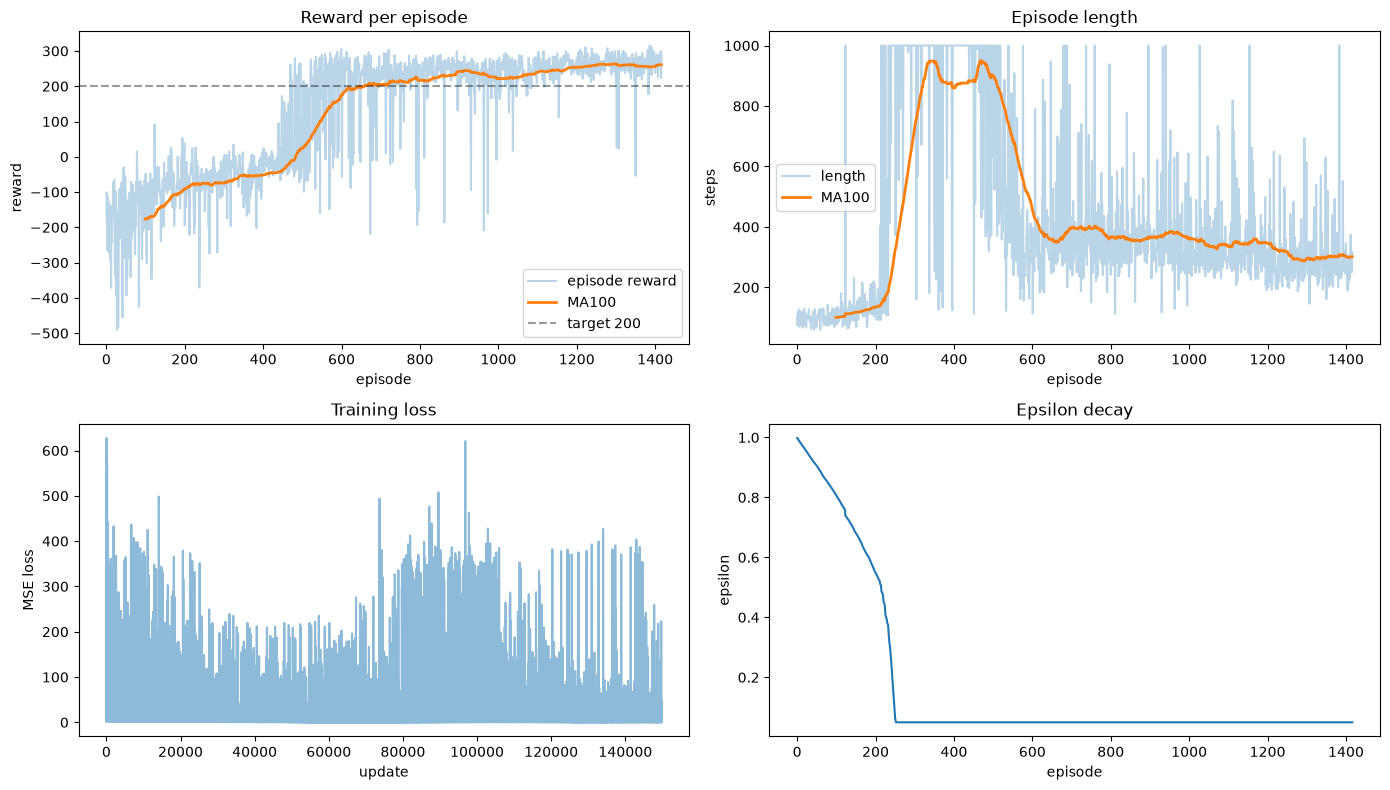

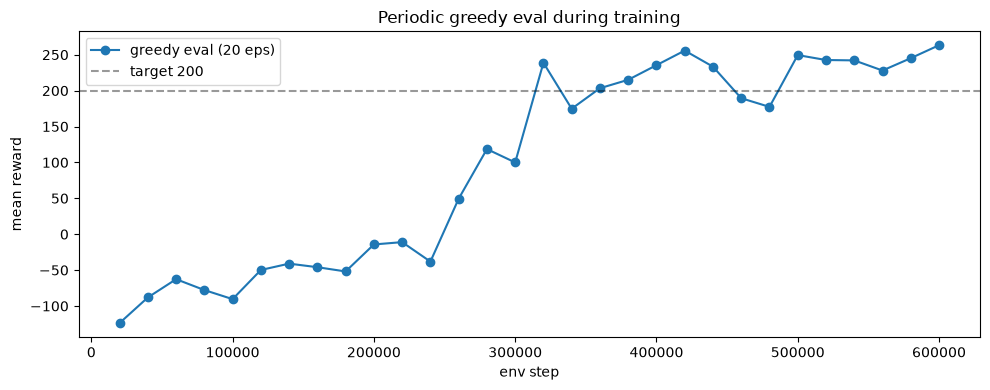

In [19]:
import json

with open("results/dqn_seed0_log.json") as f:
    log = json.load(f)
print(len(log["reward"]), "practice flights loaded")      # must print 1417

fig, axes = plt.subplots(2, 2, figsize=(14, 8))
# Reward + MA100
ax = axes[0, 0]
ax.plot(log["reward"], alpha=0.3, label="episode reward")
ma = moving_average(log["reward"], 100)
ax.plot(range(99, len(log["reward"])), ma, linewidth=2, label="MA100")
ax.axhline(200, color="black", ls="--", alpha=0.4, label="target 200")
ax.set_xlabel("episode"); ax.set_ylabel("reward")
ax.set_title("Reward per episode"); ax.legend()

# Episode length + MA100
ax = axes[0, 1]
ax.plot(log["length"], alpha=0.3, label="length")
ma_l = moving_average(log["length"], 100)
ax.plot(range(99, len(log["length"])), ma_l, linewidth=2, label="MA100")
ax.set_xlabel("episode"); ax.set_ylabel("steps")
ax.set_title("Episode length"); ax.legend()

# Loss
ax = axes[1, 0]
ax.plot(log["loss"], alpha=0.5)
ax.set_xlabel("update"); ax.set_ylabel("MSE loss")
ax.set_title("Training loss")

# Epsilon
ax = axes[1, 1]
ax.plot(log["eps"])
ax.set_xlabel("episode"); ax.set_ylabel("epsilon")
ax.set_title("Epsilon decay")
plt.savefig("results/dqn_seed0_curves.png", dpi=150)       # before the first show
plt.tight_layout(); plt.show()

# Eval mean overlay (separate figure — clearer)
steps, means = zip(*log["eval"])
fig, ax = plt.subplots(figsize=(10, 4))
ax.plot(steps, means, "o-", label="greedy eval (20 eps)")
ax.axhline(200, color="black", ls="--", alpha=0.4, label="target 200")
ax.set_xlabel("env step"); ax.set_ylabel("mean reward")
ax.set_title("Periodic greedy eval during training"); ax.legend()
plt.savefig("results/dqn_seed0_exam_curve.png", dpi=150)   # before the second show
plt.tight_layout(); plt.show()

## 8. Termination statistics

1417 practice flights: {'crash': 272, 'out_of_viewport': 30, 'truncated': 232, 'at_rest': 883}
first 200: {'crash': 195, 'out_of_viewport': 4, 'truncated': 1}
last 200:  {'at_rest': 196, 'crash': 3, 'truncated': 1}


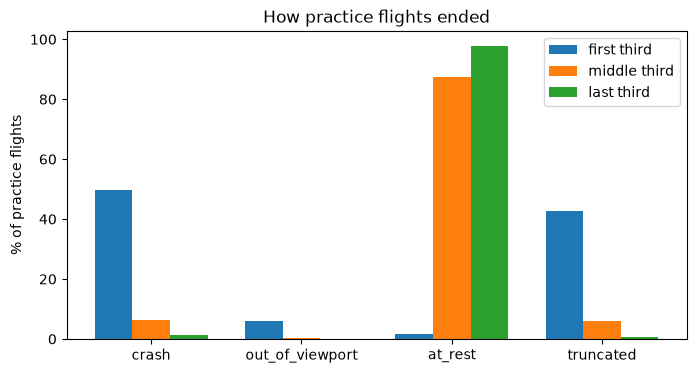

crash      | 100 flights | fall speed 0.19 | sideways 0.39 | tilt 0.38
at_rest    | 100 flights | fall speed 0.00 | sideways 0.00 | tilt 0.01
truncated  | 100 flights | fall speed 0.02 | sideways 0.05 | tilt 0.04


In [20]:
from collections import Counter
reasons = log["reason"]; n = len(reasons)
print(n, "practice flights:", dict(Counter(reasons)))
print("first 200:", dict(Counter(reasons[:200])))
print("last 200: ", dict(Counter(reasons[-200:])))

labels = ["crash", "out_of_viewport", "at_rest", "truncated"]
parts = {"first third": reasons[:n//3], "middle third": reasons[n//3:2*n//3], "last third": reasons[2*n//3:]}
fig, ax = plt.subplots(figsize=(8, 4))
for k, (name, chunk) in enumerate(parts.items()):
    c = Counter(chunk)
    ax.bar(np.arange(4) + k*0.25, [100*c[l]/len(chunk) for l in labels], 0.25, label=name)
ax.set_xticks(np.arange(4) + 0.25); ax.set_xticklabels(labels)
ax.set_ylabel("% of practice flights"); ax.set_title("How practice flights ended"); ax.legend()
plt.savefig("results/dqn_seed0_endings.png", dpi=150); plt.show()

# black box: how each kind of flight ended (last 100 of each kind)
for kind in ["crash", "at_rest", "truncated"]:
    boxes = [b for b, r in zip(log["black_box"], reasons) if r == kind][-100:]
    if boxes:
        print(f"{kind:10s} | {len(boxes):3d} flights | fall speed {np.mean([abs(b['vy']) for b in boxes]):.2f}"
              f" | sideways {np.mean([abs(b['vx']) for b in boxes]):.2f}"
              f" | tilt {np.mean([abs(b['angle']) for b in boxes]):.2f}")

## 9. Evaluation: 100 episodes, no exploration

Eval over 100 episodes (no exploration):
  mean=256.85  std=25.68  min=127.54  max=307.53
  end reasons: {'at_rest': 98, 'truncated': 2}
flights scoring 200+: 98/100 | SOLVED


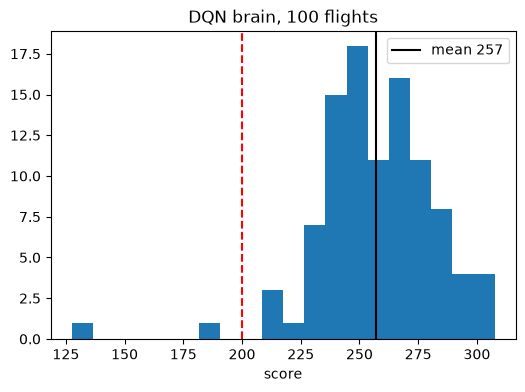

In [21]:
os.makedirs("results", exist_ok=True)

def load_net(path):
    net = QNetwork(STATE_DIM, N_ACTIONS)
    net.load_state_dict(torch.load(path))
    net.eval()
    return net

exam_env = make_env()
net = load_net("models/dqn.pt")                      # the delivered brain (best = final for seed 0)
stats = evaluate(exam_env, lambda s: select_action(net, s, 0.0),
                 n_episodes=100, seed=50_000)
print(f"flights scoring 200+: {int((stats['rewards'] >= 200).sum())}/100 | "
      f"{'SOLVED' if stats['mean'] >= 200 else 'not solved'}")

fig, ax = plt.subplots(figsize=(6, 4))
ax.hist(stats["rewards"], bins=20); ax.axvline(200, color="r", ls="--")
ax.axvline(stats["mean"], color="k", label=f"mean {stats['mean']:.0f}")
ax.set_title("DQN brain, 100 flights"); ax.set_xlabel("score"); ax.legend()
plt.savefig("results/dqn_seed0_exam.png", dpi=150); plt.show()
exam_env.close()

## 10. Several seeds

 training the remaining pilots in seed 1 and seed 2. 

In [22]:
for sd in [1, 2]:
    if os.path.exists(f"results/dqn_seed{sd}_log.json"):
        print(f"seed {sd} already trained, skipping")
    else:
        print(f"=== training seed {sd} ===")
        train_dqn(sd)

seed 1 already trained, skipping
seed 2 already trained, skipping


seed 0 (live from dqn.pt): mean=256.8, std=25.7
seed 1 (recorded from Section 10): mean=235.0, std=75.4
seed 2 (recorded from Section 10): mean=249.9, std=39.8

seed |   mean |  std | 200+ flights | first exam >= 200 at step | train minutes
   0 |  256.8 | 25.7 |  98/100      |                   320000 |  43.2
   1 |  235.0 | 75.4 |  87/100      |                   300000 |  49.1
   2 |  249.9 | 39.8 |  94/100      |                   440000 |  78.0
average of the 3 means: 247.2 | spread between seeds: 9.1


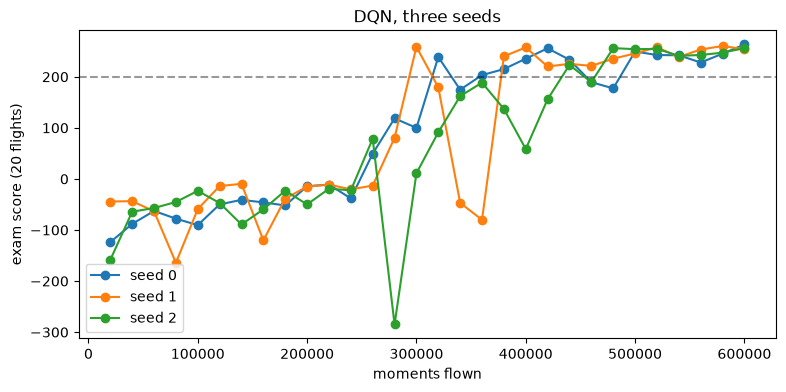

In [23]:
import os
import numpy as np
import matplotlib.pyplot as plt

exam_env = make_env()
rows, curves = [], {}

# Recorded stats from the original run, since the seed 1/2 .pt files were deleted for delivery
RECORDED_STATS = {
    1: {"mean": 235.0, "std": 75.4, "k": 87},
    2: {"mean": 249.9, "std": 39.8, "k": 94}
}

for sd in SEEDS:
    with open(f"results/dqn_seed{sd}_log.json") as f:
        lg = json.load(f)
    
    # Find the first step where the exam scored >= 200
    first = next((s for s, m in lg["eval"] if m >= 200), None)
    train_time = lg["train_time"] / 60

    if sd == 0:
        # Seed 0 uses the shipped dqn.pt (which is the 600k final)
        net = QNetwork(STATE_DIM, N_ACTIONS)
        net.load_state_dict(torch.load("models/dqn.pt", map_location="cpu", weights_only=True))
        net.eval()
        st = evaluate(exam_env, lambda s: select_action(net, s, 0.0),
                      n_episodes=100, seed=50_000, verbose=False)
        k = int((st["rewards"] >= 200).sum())
        rows.append((sd, st["mean"], st["std"], k, first, train_time))
        print(f"seed 0 (live from dqn.pt): mean={st['mean']:.1f}, std={st['std']:.1f}")
    else:
        # Seeds 1 and 2 use recorded values
        r = RECORDED_STATS[sd]
        rows.append((sd, r["mean"], r["std"], r["k"], first, train_time))
        print(f"seed {sd} (recorded from Section 10): mean={r['mean']:.1f}, std={r['std']:.1f}")

    curves[sd] = lg["eval"]

exam_env.close()

print("\nseed |   mean |  std | 200+ flights | first exam >= 200 at step | train minutes")
for sd, m, s, k, f, t in rows:
    print(f"{sd:>4} | {m:6.1f} | {s:4.1f} | {k:>3}/100      | {str(f):>24} | {t:5.1f}")
print("average of the 3 means:", round(float(np.mean([r[1] for r in rows])), 1),
      "| spread between seeds:", round(float(np.std([r[1] for r in rows])), 1))

fig, ax = plt.subplots(figsize=(9, 4))
for sd, ev in curves.items():
    xs, ys = zip(*ev); ax.plot(xs, ys, marker="o", label=f"seed {sd}")
ax.axhline(200, color="k", ls="--", alpha=0.4)
ax.set_xlabel("moments flown"); ax.set_ylabel("exam score (20 flights)")
ax.set_title("DQN, three seeds"); ax.legend()
plt.savefig("results/dqn_seeds.png", dpi=150); plt.show()

## 11. Experiment: variations

In [24]:
EXP_STEPS = 400_000
variants = {"target_every_250": 250, "target_every_4000": 4000}   # baseline = 1000, already trained
for name, every in variants.items():
    if os.path.exists(f"results/dqn_seed0_{name}_log.json"):
        print(f"{name} already done, skipping"); continue
    print(f"=== {name} ===")
    hp = {**HP, "target_update_every": every, "total_steps": EXP_STEPS}
    train_dqn(0, hp=hp, tag=f"_{name}")

target_every_250 already done, skipping
target_every_4000 already done, skipping


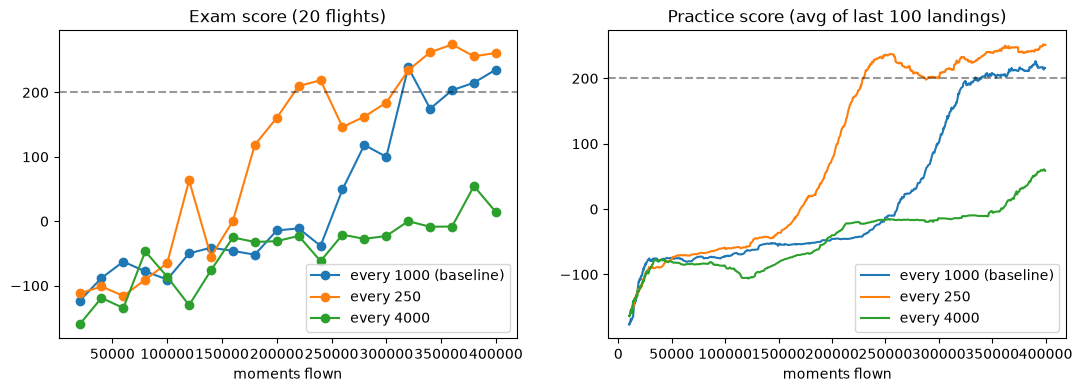

variant               | first exam >= 200 | avg of last 5 exams | practice avg at 400k | landings
every 1000 (baseline) |            320000 |               213.5 |                216.0 | 816
every 250             |            220000 |               257.7 |                251.3 | 959
every 4000            |              None |                10.5 |                 58.7 | 659


In [25]:
import json
EXP_STEPS = 400_000        # compare all three runs over their first 400,000 moments
runs = {"every 1000 (baseline)": "results/dqn_seed0_log.json",
        "every 250": "results/dqn_seed0_target_every_250_log.json",
        "every 4000": "results/dqn_seed0_target_every_4000_log.json"}
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
rows = []
for name, path in runs.items():
    with open(path) as f:
        lg = json.load(f)
    ev = [(s, m) for s, m in lg["eval"] if s <= EXP_STEPS]
    xs, ys = zip(*ev)
    axes[0].plot(xs, ys, marker="o", label=name)
    cum = np.cumsum(lg["length"]); n_ep = int((cum <= EXP_STEPS).sum())
    ma = moving_average(lg["reward"][:n_ep], 100)
    axes[1].plot(cum[99:n_ep], ma, label=name)
    first = next((s for s, m in ev if m >= 200), None)
    rows.append((name, first, float(np.mean(ys[-5:])), float(ma[-1]), n_ep))
for ax, t in zip(axes, ["Exam score (20 flights)", "Practice score (avg of last 100 landings)"]):
    ax.axhline(200, color="k", ls="--", alpha=0.4); ax.set_xlabel("moments flown"); ax.set_title(t); ax.legend()
plt.savefig("results/dqn_target_update_experiment.png", dpi=150); plt.show()

print("variant               | first exam >= 200 | avg of last 5 exams | practice avg at 400k | landings")
for name, first, last5, ma_end, n_ep in rows:
    print(f"{name:21s} | {str(first):>17} | {last5:19.1f} | {ma_end:20.1f} | {n_ep}")

In [26]:
for sd in SEEDS:
    with open(f"results/dqn_seed{sd}_log.json") as f:
        lg = json.load(f)
    ev = [(s, m) for s, m in lg["eval"] if s <= 400_000]
    print(sd, "avg of last 5 exams at 400k:", round(float(np.mean([m for _, m in ev[-5:]])), 1))

0 avg of last 5 exams at 400k: 213.5
1 avg of last 5 exams at 400k: 110.0
2 avg of last 5 exams at 400k: 127.5


## 12. Conclusion, failures, insights

### Solved
**Claim.** The DQN solves Lunar Lander on all three seeds.
**Proof.** Seed 0, exam A (100 flights, eval seed 1000): mean 252.05, std 51.0, min -112.18; endings 92 `at_rest` / 7 `truncated` / 1 `out_of_viewport`. Exam B (eval seed 50 000): mean 256.85, std 25.7, min 127.54; 98 `at_rest` / 2 `truncated`. Final nets, 100 flights, seeds 0/1/2: 256.8 / 235.0 / 249.9, with 98 / 87 / 94 flights at 200+. Random baseline: -192.1, 92 crashes.
**Limit.** "Solved" is a mean. Seed 1 has std 75 and 13 of its 100 flights below 200. The two seed-0 exams differ by 5 points, and only one is clean — exam A has a -112 flight.

### The baseline prediction
**Claim.** I predicted ~-200, crashes, ~45 moments. First two right, length off by 2×.
**Proof.** Random: -192.08, 92 crash / 8 out of viewport, 90.03 moments. Do-nothing: 70.4 moments, 100/100 crash — so ~70 moments are gravity, ~20 random buttons.
**Limit.** One seed; do-nothing ≠ random, so the 70/20 split is approximate.

### Long plateau, late take-off — and 232 timeouts in between
**Claim.** Most of training looks like failure; scores climb late, and the plateau contains a distinct failure mode.
**Proof.** Seed 1 evals: -44.2 at 20k, -120.2 at 160k, 80.5 at 280k, 258.8 at 300k. ε reached its floor of 0.05 at step 50 000, and scores kept climbing after that. Endings agree: first 200 flights 195 crash / 4 off-screen; last 200, 196 `at_rest` / 3 crash. In between, 232 of 1,417 flights hit the step limit — almost absent in the first 200 and last 200 flights, so they fall in between.
**Limit.** The take-off point moves 140k moments between seeds. I never varied ε, so this is a timeline, not a cause. I did not test why the timeouts happen. One possibility is hovering on the ground or in the air, which the black box could check.

### Crashes end with drift and tilt
**Claim.** Trained crashes end with horizontal velocity and rotation.
**Proof.** Last 100 crashes: |vx| 0.39, |tilt| 0.38 rad (~22°). At-rest flights end at ~0 by definition of at rest.
**Limit.** Black box stores only the final state — no trajectory, no spin (`state[5]`); one seed.

### Reproducibility
Same seed, same machine, same result.

### The experiment, and the noise that limits it
**The yardstick.** At 400k the same recipe scored **213.5, 110.0, 127.5** on seeds 0/1/2. That ~100-point spread is the noise floor; anything smaller is not evidence.

**Every 250.** First crossed 200 at 220k (209.9), then regressed to 146.3 at 260k and 162.4 at 280k before recovering; average of the last five exams at 400k: **257.7** vs 213.5 for the baseline. **Limit:** one run, baseline is seed 0 — the luckiest of the three at 400k. It also shows the same pass-then-regress pattern I criticise in seed 1, so "reached the bar earlier in this run" is the honest claim.

**Every 4000.** Never reached 200 within 400k. Last-five exams 10.5; practice MA100 58.7 vs 216.0. Train MA100 was still climbing at the end (33.2 at 380k → 58.7 at 400k), though exams stayed flat and noisy (0.1, -8.5, -8.2, 54.6, 14.3). **Limit:** far outside the noise, so "did not reach 200 in 400k" is safe; "never would" is not.

**Why more frequent updates can help.** A target refreshed every 250 steps lags the learning brain by at most 250 moments, against 1 000 or 4 000 — so reward reaches the copy sooner, at the cost of a target that moves under the bootstrap. The 250 run's mid-training wobble (218.9 at 240k → 146.3 at 260k) fits that cost, though a 20-flight exam has SE ≈ 6–17, so this is suggestive.

### Honest failures
1. **`end_reason` bug.** My first version used the rocket's x position in world units (≈10 at the pad) when it should have used `state[0]`, the normalized x (pad 0, edges ±1). Result: 96 of 100 baseline flights labelled `out_of_viewport`. After the fix, the same baseline reads 92 crash / 8 out of viewport.
2. **Lost log.** One run's log was lost after a restart and had to be regenerated — hence the notebook skips any seed that already has a log.
3. **A 300k attempt was too short.** Seed 0 first passes 200 only at 320k, so at 300k the baseline itself looks unsolved. Main runs use 600k; the variant experiment uses 400k.
4. **20-flight exams are noisy but not that noisy.** SE ≈ 6–17 points, so ±30 explains small wiggles. Seed 1's -46.9 → -80.0 → 240.0 across 340k–380k is real policy instability, not sampling.
5. **Training time unstable.** 43.2 / 49.1 / 78.0 minutes for the same 600k moments. Most likely machine load (power mode, heat), not measured.
6. **Seed 1 regressed after passing.** First ≥200 at 300k with 258.8; last-five at 400k only 110.0; final 100-flight 235.0 (std 75.4, 87/100). "First pass" flatters a run.

### Limits
One run per variant. 20-flight exams during training. Variant baseline is the luckiest seed. No PPO comparison. No ablation of buffer, lr, batch, net, ε schedule or γ. One environment, one machine. Black box = final states only.

### Next
3–5 seeds per variant with 100-flight exams; longer budget for 4000; Double DQN; decouple ε decay from step count; PPO comparison.